In [10]:
import tensorflow as tf
import matplotlib.pyplot as plt
from keras.datasets import cifar10
import numpy as np
import os

In [2]:
# Load the model
(x_train, y_train), (x_test, y_test) = cifar10.load_data()

x_train, x_test = x_train / 255.0, x_test / 255.0

num_classes = 10
y_train = tf.keras.utils.to_categorical(y_train, num_classes)
y_test  = tf.keras.utils.to_categorical(y_test , num_classes)

170498071/170498071 ━━━━━━━━━━━━━━━━━━━━ 17s 0us/step


In [3]:
# Build the CNN model
model = tf.keras.models.Sequential([
    
    tf.keras.layers.Conv2D(32, (3,3), activation='relu', padding='same', input_shape=(32,32,3)),
    tf.keras.layers.MaxPooling2D(2,2),

    tf.keras.layers.Conv2D(64, (3,3), activation='relu', padding='same'),
    tf.keras.layers.MaxPooling2D(2,2),

    tf.keras.layers.Conv2D(64, (3,3), activation='relu', padding='same'),
    tf.keras.layers.Flatten(),

    tf.keras.layers.Dense(64, activation='relu'),
    tf.keras.layers.Dense(num_classes, activation='softmax')
])

model.summary()

c:\Users\abudd\School Programs\CSH\brickid\training\.venv\Lib\site-packages\keras\src\layers\convolutional\base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 32, 32, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 16, 16, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 16, 16, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 8, 8, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 8, 8, 64)       │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 4096)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │       262,208 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 319,178 (1.22 MB)

 Trainable params: 319,178 (1.22 MB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
# Setup Checkpoints
# Since you're only saving weights, you should use the .weights.h5 extension.
# If you're saving the whole model, you would use the .keras extension instead
checkpoint_path = "training_1/cp.weights.h5"
checkpoint_dir = os.path.dirname(checkpoint_path)

# Create a callback that saves the model's weights
cp_callback = tf.keras.callbacks.ModelCheckpoint(filepath=checkpoint_path,
                                                 save_weights_only=True,
                                                 verbose=1)

# Set training options
model.compile(  optimizer='adam',
                loss='categorical_crossentropy',
                metrics=['accuracy'])

# Train the model
history = model.fit(x_train, y_train,
                    epochs=15,
                    batch_size=64,
                    validation_split=0.2,
                    verbose=2,
                    callbacks=[cp_callback])

Epoch 1/15
625/625 - 9s - 15ms/step - accuracy: 0.4434 - loss: 1.5307 - val_accuracy: 0.5551 - val_loss: 1.2745
Epoch 2/15
625/625 - 7s - 12ms/step - accuracy: 0.5923 - loss: 1.1498 - val_accuracy: 0.6299 - val_loss: 1.0687
Epoch 3/15
625/625 - 7s - 12ms/step - accuracy: 0.6578 - loss: 0.9727 - val_accuracy: 0.6745 - val_loss: 0.9284
Epoch 4/15
625/625 - 7s - 11ms/step - accuracy: 0.6996 - loss: 0.8567 - val_accuracy: 0.6784 - val_loss: 0.9288
Epoch 5/15
625/625 - 7s - 11ms/step - accuracy: 0.7316 - loss: 0.7653 - val_accuracy: 0.7143 - val_loss: 0.8349
Epoch 6/15
625/625 - 8s - 12ms/step - accuracy: 0.7574 - loss: 0.6919 - val_accuracy: 0.6984 - val_loss: 0.9023
Epoch 7/15
625/625 - 10s - 16ms/step - accuracy: 0.7830 - loss: 0.6205 - val_accuracy: 0.7226 - val_loss: 0.8311
Epoch 8/15
625/625 - 9s - 15ms/step - accuracy: 0.8017 - loss: 0.5578 - val_accuracy: 0.7127 - val_loss: 0.8735
Epoch 9/15
625/625 - 8s - 13ms/step - accuracy: 0.8237 - loss: 0.4991 - val_accuracy: 0.7190 - val_loss

In [5]:
# Evaluate the model
test_loss, test_acc = model.evaluate(x_test, y_test, verbose=0)

print(f"Test accuracy = {test_acc:.3f}")

Test accuracy = 0.701


In [ ]:
# Use it to predict shtuff
predictions = model.predict(x_test)
print("Predicted class:", np.argmax(predictions[0]))
print("Actual class:", np.argmax(y_test[0]))

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step
Predicted class: 8
Actual class: 8


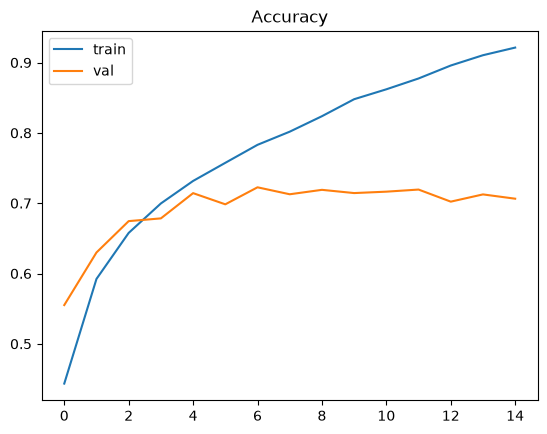

In [9]:
# Visualize accuracy
plt.plot(history.history['accuracy'], label='train')
plt.plot(history.history['val_accuracy'], label='val')
plt.legend()
plt.title('Accuracy')
plt.show()

In [ ]:
# Save the model
model.save('my_model.keras')

In [12]:
# Load a model for testing
test_model = tf.keras.models.load_model("my_model.keras")

In [14]:
# Test the first 9 image
prediction = test_model.predict(x_test)
for i in range(9):
    print(f"(Predicted, Actual): ({np.argmax(prediction[i])}, {np.argmax(y_test[0])})")

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step
(Predicted, Actual): (5, 3)
(Predicted, Actual): (8, 3)
(Predicted, Actual): (8, 3)
(Predicted, Actual): (0, 3)
(Predicted, Actual): (4, 3)
(Predicted, Actual): (6, 3)
(Predicted, Actual): (1, 3)
(Predicted, Actual): (2, 3)
(Predicted, Actual): (3, 3)


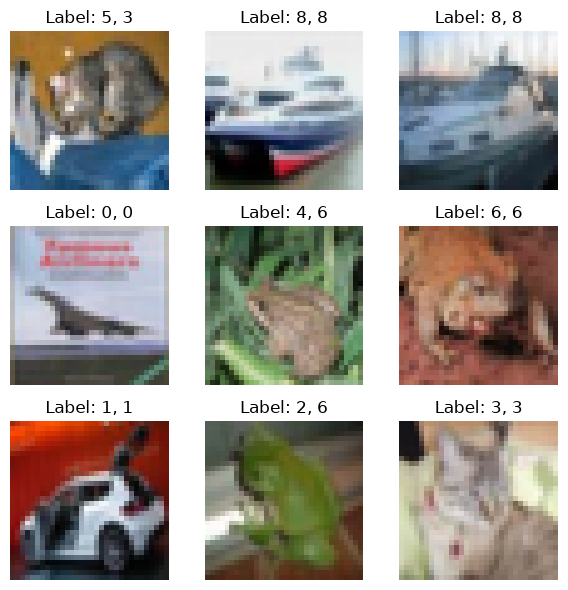

In [17]:
# Display first 9 images in the testing dataset
fig, axes = plt.subplots(3, 3, figsize=(6, 6))
for i, ax in enumerate(axes.flatten()):
  ax.imshow(x_test[i], cmap='gray')
  ax.set_title(f'Label: {np.argmax(prediction[i])}, {np.argmax(y_test[i])}')
  ax.axis('off')

plt.tight_layout()
plt.show()